# Introduction to Advantage Actor-Critic (A2C) 
In Reinforcement Learning, Advantage Actor-Critic (A2C) combines policy-based methods (the actor) and value-based methods (the critic)

- the actor $\pi_{\theta}(a|s)$ decides which action to take based on state features

- the Critic $V(s)$ evaluates how good the state is, acting as a baseline

- the Advantage $A(s,a)=r − V(s)$ measures whether the reward received was better or worse than expected, reducing variance in policy updates

In [49]:
import numpy
import matplotlib.pyplot as plt
plt.rcParams['savefig.dpi'] = 300

n_states    = 20
n_actions   = 3

# random state, here 1 x 128 dims vector
state = numpy.random.randn(1, n_states)

# simulate toy model - linear projection
# real RL uses neural networks
actor_w  = 0.1*numpy.random.randn(n_states, n_actions)
critic_w = 0.01*numpy.random.randn(n_states, 1)


# Actor Forward Pass & Action Sampling

The actor computes raw preference scores (logits) via linear projection, converts them into a probability distribution via the softmax function, and samples an executable discrete action.

- 1, logits : $l(s) = s\theta$
- 2, probs : $\pi_{\theta}(a∣s)=softmax(l(s))$
- 3, action sampling : $a \sim \pi_{\theta}(.|s)$



In [50]:
# 1. Actor forward pass, obtain logits
logits = state @ actor_w

# 2. Softmax: logits to probabilities
tmp = numpy.exp(logits)
probs = tmp / numpy.sum(tmp, axis=1, keepdims=True)

# 3. Sample action from this distribution
action = numpy.random.choice([0, 1, 2], size=1, p=probs[0])[0]


print("logits           :   ", logits)
print("probs            :   ", probs)
print("chosen action    :   ", action)


logits           :    [[ 0.07325017  0.70295154 -0.37500821]]
probs            :    [[0.28443113 0.53389144 0.18167743]]
chosen action    :    1


# plot the actor output

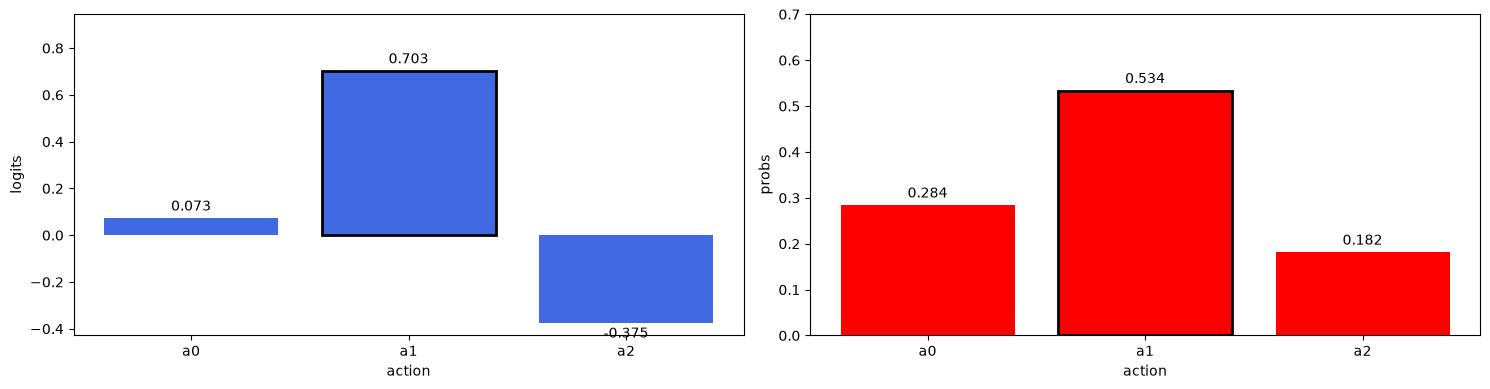

In [51]:
actions = ["a0", "a1", "a2"]


data_list = [logits[0], probs[0]]
labels = ["logits", "probs"]
colors = ["royalblue", "red"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Plot all three in a clean loop
for i, (ax, y_vals, ylabel, color) in enumerate(zip(axes, data_list, labels, colors)):
    bars = ax.bar(actions, y_vals, color=color)
    
    # Use integer formatting for the sample counts, and float for logits/probs
    fmt_str = "%d" if i == 2 else "%.3f"
    ax.bar_label(bars, fmt=fmt_str, padding=3)
    
    ax.set_xlabel("action")
    ax.set_ylabel(ylabel)

    bars[action].set_edgecolor('black')
    bars[action].set_linewidth(2)
    
    # Add top headroom so labels don't touch the top border
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(ymin, ymax * 1.25)

plt.tight_layout()
plt.savefig("a2c_logits_actions.png", dpi=300)

plt.show()



# Critic Evaluation & Advantage Calculation

The critic evaluates the state value $V(s)=s\Phi$. 

We then observe a direct reward r from the environment and calculate the advantage:
$A=r − V(s)$

- if $A>0$, the action performed better than the critic's expectation; 
- if $A<0$, it performed worse

In [52]:
# Evaluate state value using the linear critic model
v = state @ critic_w
print("estimated state value v =", v[0, 0])

# Simulate receiving a direct reward from the environment
reward = numpy.random.rand()
print("received reward =", reward)

# Compute the advantage using the critic baseline
advantage = reward - v[0, 0]
print("advantage =", advantage)

estimated state value v = 0.012722896609297174
received reward = 0.5309717267662479
advantage = 0.5182488301569508


# Parameter Updates (Training Step)

update both models using gradient descent/ascent:

1, **critic update** : Minimize the squared error loss
 $$L(\Phi)= \frac{1}{2}(V(s) - r)^2$$

2, **actor update** : Scale the policy gradient by the advantage A 

the gradient of the log-probability for the chosen action is given by 

$$\nabla_{\theta} log \pi_{\theta}(a|s) = s^T(e_a - \pi_{\theta}(s))$$


In [53]:
learning_rate = 0.1

# 1, critic update, MSE loss
critic_grad = state.T * (v[0, 0] - reward)
critic_w -= learning_rate * critic_grad



# 2, actor update

# create one-hot encoding for the chosen action
one_hot_action = numpy.zeros((1, n_actions))
one_hot_action[0, action] = 1.0

# compute log-probability gradient for the actor weights: state.T * (one_hot - probs)
actor_grad = state.T @ (one_hot_action - probs)

# update actor weights using policy gradient direction scaled by the advantage
actor_w += learning_rate * advantage * actor_grad


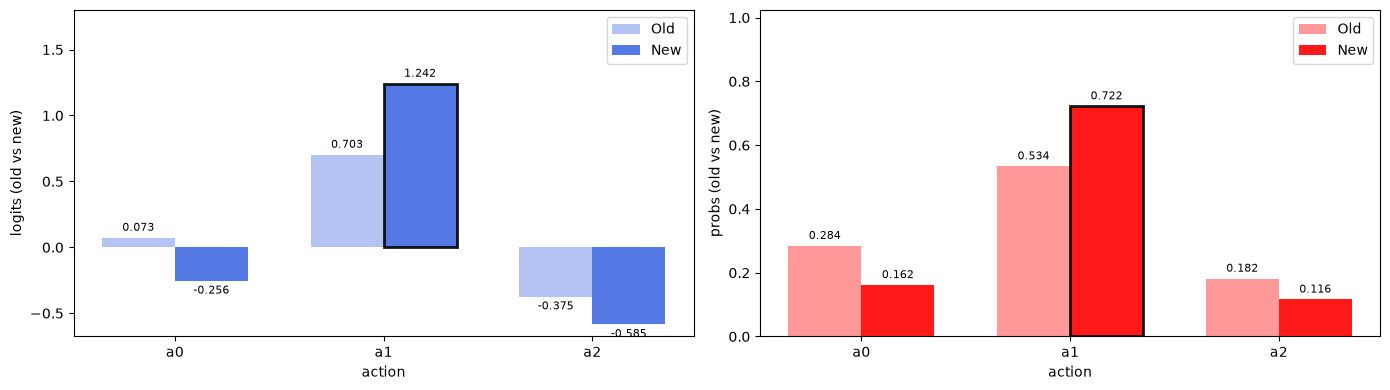

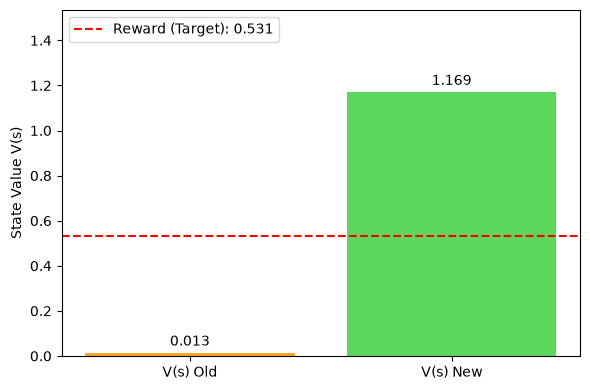

In [54]:
# 1. Actor forward pass, obtain logits
logits_new = state @ actor_w

# 2. Softmax: logits to probabilities
tmp = numpy.exp(logits_new)
probs_new = tmp / numpy.sum(tmp, axis=1, keepdims=True)

# Compute new state value using the updated critic weights
v_new_val = state @ critic_w



# --- 1. Actor Outputs Comparison Plot (Logits & Probs) ---
actions = ["a0", "a1", "a2"]

data_list = [
    (logits[0], logits_new[0]),
    (probs[0], probs_new[0])
]
labels = ["logits (old vs new)", "probs (old vs new)"]
colors = ["royalblue", "red"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for i, (ax, (y_old, y_new), ylabel, color) in enumerate(zip(axes, data_list, labels, colors)):
    x = numpy.arange(len(actions))
    width = 0.35
    
    bars_old = ax.bar(x - width/2, y_old, width, label='Old', color=color, alpha=0.4)
    bars_new = ax.bar(x + width/2, y_new, width, label='New', color=color, alpha=0.9)
    
    # Highlight the chosen action bar
    bars_new[action].set_edgecolor('black')
    bars_new[action].set_linewidth(2)
    
    ax.set_xticks(x)
    ax.set_xticklabels(actions)
    ax.bar_label(bars_old, fmt="%.3f", padding=3, fontsize=8)
    ax.bar_label(bars_new, fmt="%.3f", padding=3, fontsize=8)
    
    ax.set_xlabel("action")
    ax.set_ylabel(ylabel)
    ax.legend()
    
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(ymin, ymax * 1.35)

#fig.suptitle(f"Actor Update Comparison (Chosen Action: a{action} framed in black)", fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig("a2c_logits_actions_comparison.png", dpi=300)
plt.show()


# --- 2. Separate Critic Value Comparison Plot ---
fig_val, ax_val = plt.subplots(figsize=(6, 4))
value_labels = ['V(s) Old', 'V(s) New']
value_data = [v[0, 0], v_new_val[0, 0]]
colors_val = ['darkorange', 'limegreen']

bars_val = ax_val.bar(value_labels, value_data, color=colors_val, alpha=0.8)
ax_val.bar_label(bars_val, fmt="%.3f", padding=3)   

# Draw a horizontal line representing the actual reward received (critic target)
ax_val.axhline(y=reward, color='red', linestyle='--', label=f'Reward (Target): {reward:.3f}')

ax_val.set_ylabel("State Value V(s)")
#ax_val.set_title("Critic Value Update Comparison")
ax_val.legend(loc='upper left')

ymin, ymax = ax_val.get_ylim()
ax_val.set_ylim(min(ymin, reward) * 1.1, max(ymax, reward) * 1.25)

plt.tight_layout()
plt.savefig("a2c_critic_value_comparison.png", dpi=300)
plt.show()